In [1]:
!pip install -q imbalanced-learn

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("1. Loading dataset...")
heart_data = fetch_openml(name="heart-c", version=1, as_frame=True)
df = heart_data.frame

# Dynamically rename the last column (which is the target class) to 'target'
target_col = df.columns[-1]
df = df.rename(columns={target_col: 'target'})

# Clean target variable (0 = No Disease, 1 = Disease present)
# OpenML's heart-c target values are typically '<50' (no disease / 0) and '>50_1', '>50_2', etc. (disease / 1)
df["target"] = df["target"].apply(lambda x: 0 if str(x).strip() == '<50' else 1)
df = df.dropna()

X = df.drop(columns=["target"])
X = pd.get_dummies(X, drop_first=True)
y = df["target"]

print(f"Dataset shape: {X.shape}")

1. Loading dataset...
Dataset shape: (296, 18)


In [6]:
print("2. Splitting data into train and test sets...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("3. Preprocessing and scaling features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("4. Handling class imbalance using SMOTE...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
print(f"Training set shape after SMOTE: {X_train_resampled.shape}")

2. Splitting data into train and test sets...
3. Preprocessing and scaling features...
4. Handling class imbalance using SMOTE...
Training set shape after SMOTE: (256, 18)


In [7]:
print("5. Training Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

print("6. Evaluating model performance...")
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

5. Training Random Forest Classifier...
6. Evaluating model performance...

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.88      0.91      0.89        32
           1       0.89      0.86      0.87        28

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60

ROC-AUC Score: 0.9408


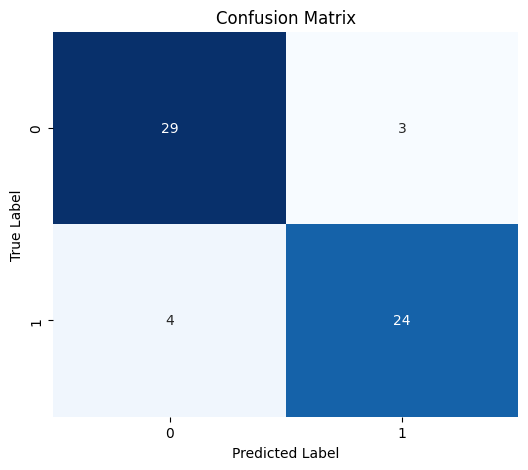

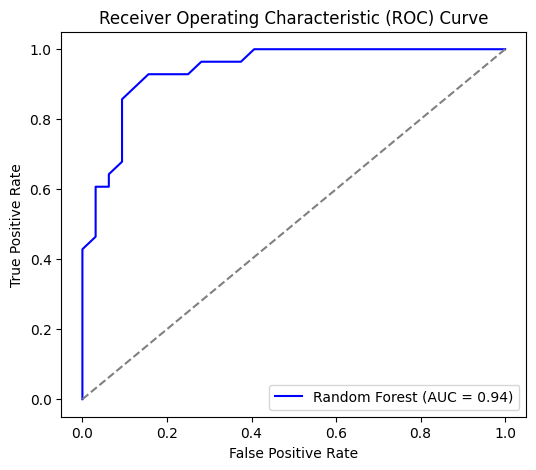

In [8]:
# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ROC Curve Plot
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="blue", label=f"Random Forest (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()